<a href="https://colab.research.google.com/github/nattaponm/Teach_HID_Doppler_KKN_summerStorm/blob/main/notebooks/03_spectrum_width_turbulence_pytda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 3: Spectrum width และความปั่นป่วนในพายุด้วย PyTDA
### Spectrum width, eddy dissipation rate (EDR) and the NCAR Turbulence Detection Algorithm (NTDA)

⏱️ เวลาเรียนโดยประมาณ **60–75 นาที** | ต้องผ่าน: Notebook 1–2

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **อธิบายว่า spectrum width ($\sigma_v$) เกิดจากอะไรบ้าง** และทำไมต้องแยกส่วนที่มาจากความปั่นป่วน
2. **อธิบายความหมายของ EDR** (eddy dissipation rate) และความสัมพันธ์กับ $\sigma_v$ ตามทฤษฎีของ Kolmogorov
3. **รัน PyTDA (NTDA)** กับข้อมูล KKN และทำแผนที่ EDR คุณภาพตีพิมพ์
4. **วิเคราะห์ EDR ในเชิงพื้นที่ เวลา และความสูง** ของพายุที่หนองบัวลำภู
5. **ตรวจความไวของผลต่อพารามิเตอร์** และบอกข้อจำกัดของการประมาณความปั่นป่วนจากเรดาร์ปฏิบัติการ

## 📖 1. แนวคิดและสมการ

### 1.1 Spectrum width มาจากไหน
ในปริมาตรวัด 1 gate (กว้าง ~2 km ที่ระยะ 120 km) เม็ดฝนเคลื่อนที่ด้วยความเร็วต่างกัน → สเปกตรัม Doppler มีความกว้าง
$$ \sigma_v^2 = \sigma_{shear}^2 + \sigma_{rot}^2 + \sigma_{fall}^2 + \sigma_{turb}^2 $$
- $\sigma_{shear}$: ลมเฉือนภายในลำคลื่น (ยิ่งไกล ลำคลื่นยิ่งกว้าง ยิ่งมาก)
- $\sigma_{rot}$: การหมุนของสายอากาศ, $\sigma_{fall}$: ความเร็วตกที่ต่างกันของเม็ด (มีผลน้อยที่มุมยกต่ำ)
- $\sigma_{turb}$: **ความปั่นป่วน** ← สิ่งที่ต้องการ

### 1.2 EDR และทฤษฎี Kolmogorov
ในช่วง inertial subrange พลังงานจลน์ส่งต่อจาก eddy ใหญ่ไปเล็กด้วยอัตรา $\varepsilon$ (m² s⁻³) ความแปรปรวนของความเร็วในปริมาตรขนาด $L$ คือ
$$ \sigma_{turb}^2 \approx C\,(\varepsilon L)^{2/3}\quad\Longrightarrow\quad \mathrm{EDR} \equiv \varepsilon^{1/3} \approx \frac{\sigma_{turb}}{\sqrt{C}\,L^{1/3}}\quad [\mathrm{m^{2/3}\,s^{-1}}] $$
$L$ ขึ้นกับขนาดปริมาตรวัด ($\approx r\,\Delta\theta$) → $\sigma_v$ ค่าเดียวกันที่ระยะไกล หมายถึง EDR **ต่ำกว่า** ที่ระยะใกล้

### 1.3 NTDA ใน PyTDA (Williams & Meymaris, 2016)
1. ให้ **ค่าความเชื่อมั่น (confidence)** แต่ละ gate จาก Z, SNR และความเรียบของ $\sigma_v$
2. แปลง $\sigma_v$ เป็น EDR ด้วยตาราง/สมการที่คิดขนาดลำคลื่นตามระยะ
3. **เฉลี่ยถ่วงน้ำหนัก** ในรัศมี `radius` (km) รอบแต่ละ gate → ลด noise

| EDR$^{1/3}$ (m$^{2/3}$ s⁻¹) | ระดับความปั่นป่วนต่ออากาศยานขนาดกลาง (ICAO Annex 3, โดยประมาณ) |
|---|---|
| < 0.1 | เรียบ – เบามาก |
| 0.1 – 0.2 | เบา (light) |
| 0.2 – 0.45 | ปานกลาง (moderate) |
| > 0.45 | รุนแรง (severe) |

> ⚙️ KKN วัด Z และ Doppler **ในรอบเดียวกัน** ทุกมุมยก จึงใช้ `split_cut=False` (ต่างจาก WSR-88D ที่มุมต่ำแยกเป็น 2 รอบ)

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล
PyTDA ต้อง compile ด้วย Cython จึงติดตั้งนานกว่า notebook อื่นเล็กน้อย

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_HID_Doppler_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio
    !pip install -q --no-build-isolation git+https://github.com/nasa/PyTDA.git
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "polar_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import polar_tools as pt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_HID_Doppler_KKN_summerStorm/data


In [2]:
snd = pt.load_profile(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
peak = pt.polar_files(DATA, "09:00", "10:45")
radar = pt.read_volume(pt.polar_files(DATA, "09:30", "09:30")[0])
meta = pt.polar_meta(radar)
reports = kt.load_reports(DATA, meta)
NK = kt.site(reports, "Na Klang")
NW = kt.box_around(meta, 102.3, 17.3, 90)
H0 = pt.isotherm_height(snd, 0.0)
print(mp.tlabel(pt.volume_time(radar)), "| ระดับ 0 °C =", f"{H0:.0f} m")

09:30 UTC (16:30 LT) | ระดับ 0 °C = 5172 m


## 📊 3. Spectrum width: แผนที่และความสัมพันธ์กับระยะ

บันทึกรูปแล้ว: figures/nb3_spectrum_width.png, figures/nb3_spectrum_width.pdf


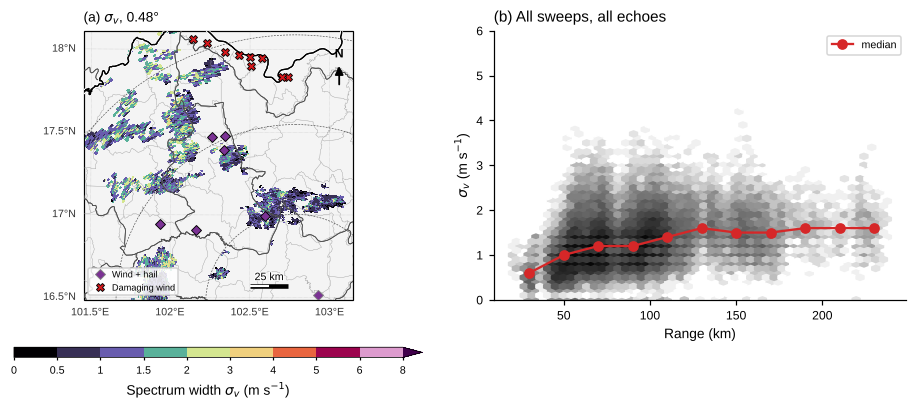

median σv ตามช่วงระยะ (m/s): {'0-20': np.float64(nan), '20-40': np.float64(0.6), '40-60': np.float64(1.0), '60-80': np.float64(1.2), '80-100': np.float64(1.2), '100-120': np.float64(1.4), '120-140': np.float64(1.6), '140-160': np.float64(1.5), '160-180': np.float64(1.5), '180-200': np.float64(1.6), '200-220': np.float64(1.6), '220-240': np.float64(1.6)}


In [3]:
w = pt.field_data(radar, "spectrum_width_qc")
rk = np.broadcast_to(radar.range["data"] / 1000, w.shape)
fig = plt.figure(figsize=(8.4, 3.6), layout="constrained")
gs = fig.add_gridspec(1, 2, width_ratios=[1.1, 1])
ax0 = fig.add_subplot(gs[0], projection=mp.get_crs(meta))
im = pt.ppi_map(ax0, radar, "spectrum_width_qc", 0, meta, kind="W", zoom=NW, title="(a) $\\sigma_v$, 0.48°")
mp.add_reports(ax0, reports)
mp.add_colorbar(fig, im, ax0, shrink=0.9)
ax1 = fig.add_subplot(gs[1])
ok = np.isfinite(w)
ax1.hexbin(rk[ok], w[ok], gridsize=(48, 24), cmap="Greys", bins="log", mincnt=1)
bins = np.arange(0, 241, 20)
med = [np.nanmedian(w[ok & (rk >= a) & (rk < a + 20)]) for a in bins[:-1]]
ax1.plot(bins[:-1] + 10, med, "o-", color="tab:red", label="median")
ax1.set_xlabel("Range (km)"); ax1.set_ylabel("$\\sigma_v$ (m s$^{-1}$)"); ax1.set_ylim(0, 6)
ax1.legend(fontsize=7); ax1.set_title("(b) All sweeps, all echoes", loc="left")
mp.save_figure(fig, "nb3_spectrum_width")
plt.show()
print("median σv ตามช่วงระยะ (m/s):", dict(zip([f"{a}-{a+20}" for a in bins[:-1]], np.round(med, 2))))

$\sigma_v$ **เพิ่มขึ้นตามระยะ** แม้ความปั่นป่วนจริงไม่ได้เพิ่ม — เพราะลำคลื่นกว้างขึ้นจึงรวมลมเฉือนและ eddy ขนาดใหญ่ไว้มากขึ้น
ดังนั้น **ห้ามใช้ $\sigma_v$ ดิบเปรียบเทียบความปั่นป่วนระหว่างพื้นที่ใกล้–ไกล** ต้องแปลงเป็น EDR ก่อน

## 🌪️ 4. คำนวณ EDR ด้วย PyTDA (09:30 UTC)

In [4]:
import time
t0 = time.time()
pt.add_edr(radar, radius=2.0)               # ห่อ pytda.calc_turb_vol(..., split_cut=False, beamwidth=1.0, gate_spacing=0.5)
print(f"PyTDA ใช้เวลา {time.time() - t0:.1f} s")
e = pt.field_data(radar, "EDR")
print(f"gate ที่มี EDR: {np.isfinite(e).sum():,} | p50 = {np.nanpercentile(e, 50):.3f}, p95 = {np.nanpercentile(e, 95):.3f}, "
      f"max = {np.nanmax(e):.3f} m^(2/3)/s")
print(f"สัดส่วน gate ระดับปานกลาง (≥ 0.20): {100 * np.nanmean(e[np.isfinite(e)] >= 0.20):.2f}%")

PyTDA ใช้เวลา 5.6 s
gate ที่มี EDR: 34,057 | p50 = 0.127, p95 = 0.187, max = 0.283 m^(2/3)/s
สัดส่วน gate ระดับปานกลาง (≥ 0.20): 2.13%


บันทึกรูปแล้ว: figures/nb3_edr_four_sweeps.png, figures/nb3_edr_four_sweeps.pdf


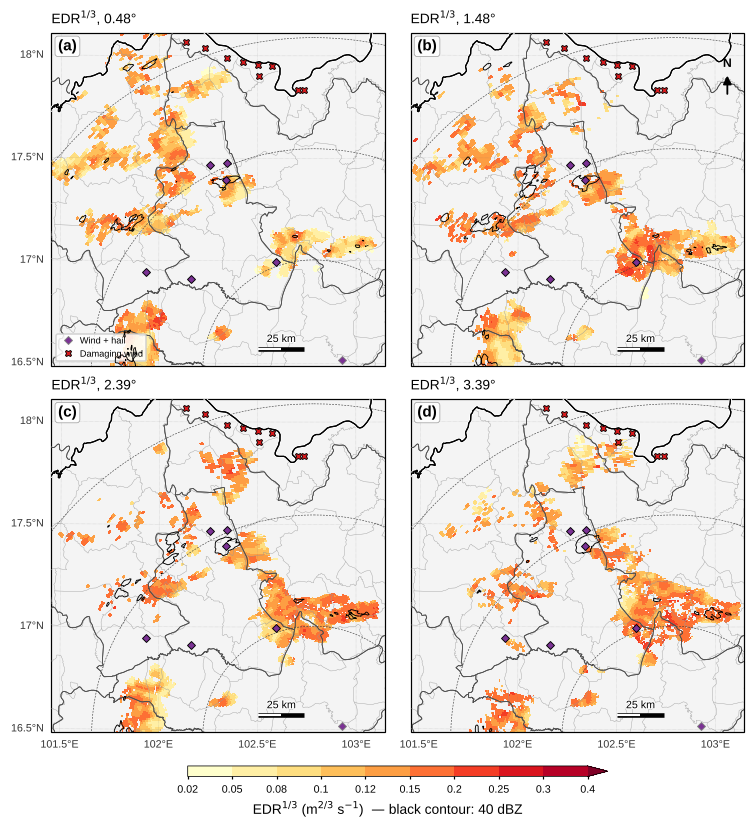

In [5]:
fig, axs = mp.map_panels(2, 2, meta, panel_width=3.4, zoom=NW)
for s, ax in enumerate(axs):
    im = pt.ppi_map(ax, radar, "EDR", s, meta, kind="EDR", zoom=NW, north=(s == 1),
                    title=f"EDR$^{{1/3}}$, {radar.fixed_angle['data'][s]:.2f}°",
                    gridline_labels=(("left",) if s % 2 == 0 else ()) + (("bottom",) if s >= 2 else ()))
    x, y, _ = radar.get_gate_x_y_z(s)
    ax.contour(x, y, np.nan_to_num(pt.field_data(radar, "reflectivity_qc", s), nan=0), levels=[40],
               colors="k", linewidths=0.6, transform=mp.get_crs(meta), zorder=6)
    mp.add_reports(ax, reports, legend=(s == 0), ms=4)
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs, label="EDR$^{1/3}$ (m$^{2/3}$ s$^{-1}$)  — black contour: 40 dBZ")
mp.save_figure(fig, "nb3_edr_four_sweeps")
plt.show()

- EDR กระจายอยู่ทั่วบริเวณที่มี echo แต่ **ค่าสูง (สีแดง) มักอยู่ใกล้แกน 40 dBZ** และเด่นขึ้นในมุมยกที่สูงขึ้น (ระดับกลางของพายุ) เช่น กลุ่มเซลล์ทางใต้ของหนองบัวลำภู
- ค่าส่วนใหญ่อยู่ในระดับ **เบา (0.1–0.2)** มีบางจุดถึงระดับปานกลาง — สอดคล้องกับพายุฤดูร้อนขนาดเซลล์เดี่ยว/กลุ่มเซลล์
- ช่องว่างในแผนที่ = gate ที่ NTDA ให้ความเชื่อมั่นต่ำ (Z หรือ SNR ต่ำ)

## ⏱️ 5. EDR ตลอดช่วงพีค 09:00–10:45 UTC และโครงสร้างแนวตั้ง

บันทึกรูปแล้ว: figures/nb3_edr_time_height.png, figures/nb3_edr_time_height.pdf


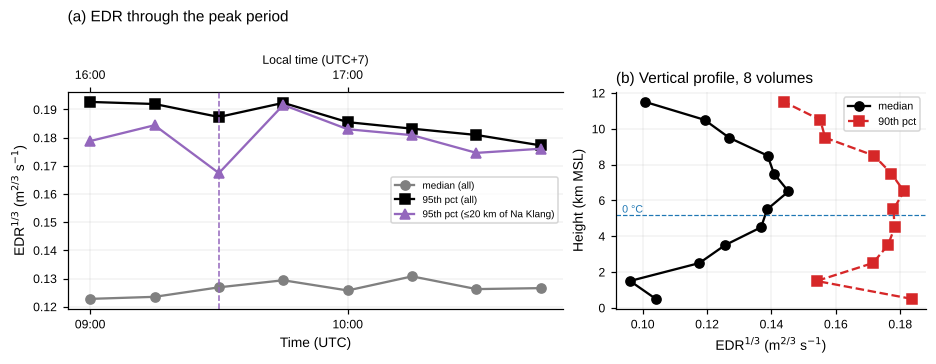

,p50_all,p95_all,p95_NaKlang,frac_moderate_%
time,,,,
2024-05-03 09:00:00,0.123,0.193,0.179,3.363
2024-05-03 09:15:00,0.123,0.192,0.184,3.381
2024-05-03 09:30:00,0.127,0.187,0.167,2.132
2024-05-03 09:45:00,0.129,0.192,0.192,3.202
2024-05-03 10:00:00,0.126,0.186,0.183,1.861
2024-05-03 10:15:00,0.131,0.183,0.181,1.308
2024-05-03 10:30:00,0.126,0.181,0.175,1.069
2024-05-03 10:45:00,0.127,0.177,0.176,0.891


In [6]:
rows, prof = [], []
for f in peak:
    r = pt.read_volume(f)
    pt.add_edr(r)
    e_ = pt.field_data(r, "EDR")
    m_nk = pt.site_gates(r, meta, NK["lon"], NK["lat"], 20)
    ok = np.isfinite(e_)
    rows.append({"time": pt.volume_time(r), "p50_all": np.nanpercentile(e_, 50), "p95_all": np.nanpercentile(e_, 95),
                 "p95_NaKlang": np.nanpercentile(e_[m_nk & ok], 95) if (m_nk & ok).sum() > 20 else np.nan,
                 "frac_moderate_%": 100 * np.mean(e_[ok] >= 0.2)})
    alt = r.gate_altitude["data"]
    prof.append(pd.DataFrame({"alt_km": alt[ok] / 1000, "edr": e_[ok]}))
ets = pd.DataFrame(rows).set_index("time")
pf = pd.concat(prof)
pf["hbin"] = pd.cut(pf["alt_km"], np.arange(0, 13, 1))
vp = pf.groupby("hbin", observed=True)["edr"].describe(percentiles=[0.5, 0.9])

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.2), layout="constrained", gridspec_kw={"width_ratios": [1.6, 1]})
axs[0].plot(ets.index, ets["p50_all"], "o-", color="0.5", label="median (all)")
axs[0].plot(ets.index, ets["p95_all"], "s-", color="k", label="95th pct (all)")
axs[0].plot(ets.index, ets["p95_NaKlang"], "^-", color="tab:purple", label="95th pct (≤20 km of Na Klang)")
axs[0].axvline(ets.index[0].replace(hour=9, minute=30), color="tab:purple", ls="--", lw=1)
axs[0].set_ylabel("EDR$^{1/3}$ (m$^{2/3}$ s$^{-1}$)"); axs[0].legend(fontsize=6.5); axs[0].grid(lw=0.3, alpha=0.5)
mp.time_axis(axs[0], interval_h=1)
axs[0].set_title("(a) EDR through the peak period", loc="left", pad=22)
hm = [b.mid for b in vp.index]
axs[1].plot(vp["50%"], hm, "o-", color="k", label="median")
axs[1].plot(vp["90%"], hm, "s--", color="tab:red", label="90th pct")
axs[1].axhline(H0 / 1000, color="tab:blue", ls="--", lw=0.8); axs[1].text(0.02, H0 / 1000 + 0.15, "0 °C", color="tab:blue", fontsize=7, transform=axs[1].get_yaxis_transform())
axs[1].set_xlabel("EDR$^{1/3}$ (m$^{2/3}$ s$^{-1}$)"); axs[1].set_ylabel("Height (km MSL)")
axs[1].legend(fontsize=7); axs[1].grid(lw=0.3, alpha=0.5); axs[1].set_title("(b) Vertical profile, 8 volumes", loc="left")
mp.save_figure(fig, "nb3_edr_time_height")
plt.show()
ets.round(3)

- (a) EDR ภาพรวมค่อนข้างคงที่ตลอดช่วงพีค (median ~0.12–0.13) และ p95 รอบนากลาง **ไม่ได้สูงกว่าภาพรวมชัดเจน** — ความปั่นป่วนที่เรดาร์เห็นกระจายทั่วพายุหลายเซลล์ ไม่ได้เด่นเฉพาะจุดรายงาน
  (สัดส่วน gate ระดับปานกลางลดลงหลัง 10:00 UTC เมื่อพายุเริ่มสลาย)
- (b) EDR **เพิ่มขึ้นตามความสูงจนถึง ~6–7 km (เหนือระดับ 0 °C เล็กน้อย)** แล้วลดลง — ตรงกับชั้นที่ updraft แรงและเกิดการเยือกแข็ง/ปล่อยความร้อนแฝง
  แต่ต้องระวัง: gate ที่สูงมาก ๆ มาจาก **ระยะไกล** (ลำคลื่นกว้าง) → ความสูงกับระยะปนกัน (confounding)

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 3.1: NTDA แก้ผลของระยะได้จริงหรือไม่?
จาก volume 09:30 UTC (`radar` ที่มี field `EDR` แล้ว) จงหา **median ของ $\sigma_v$ และ EDR ทุกช่วงระยะ 30 km**
แล้วพลอตทั้งสองตัวเทียบกับระยะ (ทำให้เป็นค่าสัมพัทธ์ เช่น หารด้วยค่าของช่วง 60–90 km) และคำนวณ Spearman correlation กับระยะ

**คำถาม:** ตัวไหนขึ้นกับระยะมากกว่า? สอดคล้องกับสมการ $\mathrm{EDR} \propto \sigma/L^{1/3}$ หรือไม่?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `df = pd.DataFrame({"r": rk.ravel(), "w": w.ravel(), "e": e.ravel()}).dropna()`
- `df.groupby(pd.cut(df.r, np.arange(0, 241, 30)), observed=True).median()`
- `from scipy.stats import spearmanr`

</details>

In [7]:
# ✍️ แบบฝึกหัด 3.1 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb3_ex31_range_dependence.png, figures/nb3_ex31_range_dependence.pdf


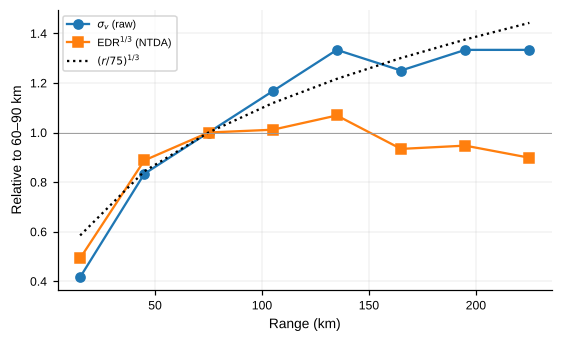

              w      e
r                     
(0, 30]     0.5  0.064
(30, 60]    1.0  0.115
(60, 90]    1.2  0.129
(90, 120]   1.4  0.130
(120, 150]  1.6  0.138
(150, 180]  1.5  0.120
(180, 210]  1.6  0.122
(210, 240]  1.6  0.116

Spearman ρ กับระยะ: σv = 0.33, EDR = 0.09
→ σv เพิ่มตามระยะชัดเจน แต่ EDR แทบคงที่ → NTDA ชดเชยขนาดปริมาตรวัด (L ∝ r) ได้ตามทฤษฎี
  ช่วง < 30 km มีตัวอย่างน้อย และลำคลื่นแคบ จึงแปลผลระวัง


In [8]:
#@title ✅ เฉลยแบบฝึกหัด 3.1
from scipy.stats import spearmanr
w = pt.field_data(radar, "spectrum_width_qc"); e = pt.field_data(radar, "EDR")
rk = np.broadcast_to(radar.range["data"] / 1000, w.shape)
df = pd.DataFrame({"r": rk.ravel(), "w": w.ravel(), "e": e.ravel()}).dropna()
g = df.groupby(pd.cut(df.r, np.arange(0, 241, 30)), observed=True)[["w", "e"]].median()
g = g[df.groupby(pd.cut(df.r, np.arange(0, 241, 30)), observed=True).size() > 50]
ref = g.iloc[[i for i, b in enumerate(g.index) if b.left == 60][0]]
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
mid = [b.mid for b in g.index]
ax.plot(mid, g["w"] / ref["w"], "o-", label="$\\sigma_v$ (raw)")
ax.plot(mid, g["e"] / ref["e"], "s-", label="EDR$^{1/3}$ (NTDA)")
ax.plot(mid, (np.array(mid) / 75.0) ** (1 / 3), "k:", label="$(r/75)^{1/3}$")
ax.axhline(1, color="0.6", lw=0.6); ax.set_xlabel("Range (km)"); ax.set_ylabel("Relative to 60–90 km")
ax.legend(fontsize=7); ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb3_ex31_range_dependence")
plt.show()
print(g.round(3))
print(f"\nSpearman ρ กับระยะ: σv = {spearmanr(df.r, df.w)[0]:.2f}, EDR = {spearmanr(df.r, df.e)[0]:.2f}")
print("→ σv เพิ่มตามระยะชัดเจน แต่ EDR แทบคงที่ → NTDA ชดเชยขนาดปริมาตรวัด (L ∝ r) ได้ตามทฤษฎี"
      "\n  ช่วง < 30 km มีตัวอย่างน้อย และลำคลื่นแคบ จึงแปลผลระวัง")

### 🧪 แบบฝึกหัด 3.2: ความปั่นป่วนสัมพันธ์กับอะไร?
ใช้ volume 09:30 UTC คำนวณ Spearman correlation ระหว่าง EDR กับ (1) $Z_H$ (2) |divergence| (3) |azimuthal shear| (ต้องแก้การพับความเร็วก่อน)
แล้วทำกราฟ box plot ของ EDR แยกตามช่วง $Z_H$ (0–20, 20–35, 35–45, ≥45 dBZ)

**คำถาม:** ทำไม EDR สัมพันธ์กับ shear มากกว่า Z? ความสัมพันธ์ที่ได้บอกเรื่องเหตุ–ผล (causality) ได้หรือไม่?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `pt.dealias_region(radar); pt.radial_divergence(radar); pt.azimuthal_shear(radar)`
- ใช้ `np.abs(...)` กับ divergence และ shear
- `pd.cut(df.z, [0, 20, 35, 45, 70])` แล้ว `df.boxplot(column="e", by="zbin")`

</details>

In [9]:
# ✍️ แบบฝึกหัด 3.2 — เขียนโค้ดของคุณที่นี่

z              0.11
abs_div        0.25
abs_azshear    0.33
Name: Spearman ρ with EDR, dtype: float64


บันทึกรูปแล้ว: figures/nb3_ex32_edr_vs_z.png, figures/nb3_ex32_edr_vs_z.pdf


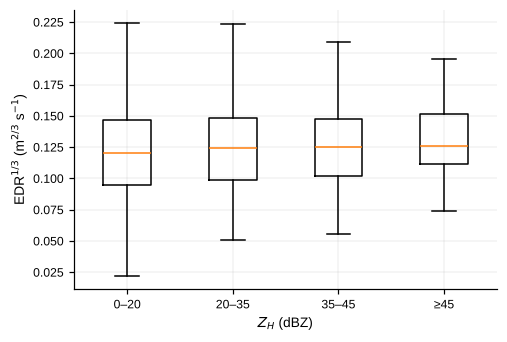


→ EDR สัมพันธ์กับ shear ของลมมากกว่า Z เพราะความปั่นป่วนเกิดจากการเฉือนของลม (shear production) ไม่ใช่จากปริมาณน้ำโดยตรง
  แต่ correlation ไม่ใช่ causality: ทั้ง EDR และ shear ถูกคำนวณจากข้อมูล Doppler ชุดเดียวกัน (σv ส่วนหนึ่งมาจาก shear ในลำคลื่น)


In [10]:
#@title ✅ เฉลยแบบฝึกหัด 3.2
pt.dealias_region(radar); pt.radial_divergence(radar); pt.azimuthal_shear(radar)
d = pd.DataFrame({"e": pt.field_data(radar, "EDR").ravel(), "z": pt.field_data(radar, "reflectivity_qc").ravel(),
                  "abs_div": np.abs(pt.field_data(radar, "DIV")).ravel(),
                  "abs_azshear": np.abs(pt.field_data(radar, "AZSHEAR")).ravel()}).dropna()
cor = pd.Series({k: spearmanr(d["e"], d[k])[0] for k in ("z", "abs_div", "abs_azshear")}, name="Spearman ρ with EDR")
print(cor.round(2))
d["zbin"] = pd.cut(d["z"], [0, 20, 35, 45, 70], labels=["0–20", "20–35", "35–45", "≥45"])
fig, ax = plt.subplots(figsize=(4.5, 3), layout="constrained")
data = [d.loc[d.zbin == b, "e"] for b in d["zbin"].cat.categories]
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(data) + 1), list(d["zbin"].cat.categories))
ax.set_xlabel("$Z_H$ (dBZ)"); ax.set_ylabel("EDR$^{1/3}$ (m$^{2/3}$ s$^{-1}$)"); ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb3_ex32_edr_vs_z")
plt.show()
print("\n→ EDR สัมพันธ์กับ shear ของลมมากกว่า Z เพราะความปั่นป่วนเกิดจากการเฉือนของลม (shear production) ไม่ใช่จากปริมาณน้ำโดยตรง"
      "\n  แต่ correlation ไม่ใช่ causality: ทั้ง EDR และ shear ถูกคำนวณจากข้อมูล Doppler ชุดเดียวกัน (σv ส่วนหนึ่งมาจาก shear ในลำคลื่น)")

### 🧪 แบบฝึกหัด 3.3: รัศมีเฉลี่ยของ NTDA มีผลแค่ไหน?
รัน `pt.add_edr(radar, radius=R, name=f"EDR_{R}")` กับ R = 1, 2, 4 km แล้วเปรียบเทียบ (1) จำนวน gate ที่มีค่า (2) p50, p95, max (3) เวลาที่ใช้
และพลอตแผนที่ EDR มุมยก 1.48° ทั้ง 3 ค่า ซูมรอบนากลาง

**คำถาม:** ถ้าต้องการหา "จุดอันตราย" ขนาดเล็กเพื่อการบิน ควรใช้ R เท่าไร? ถ้าต้องการสถิติภูมิอากาศของความปั่นป่วน ควรใช้เท่าไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- จับเวลา: `t0 = time.time(); ...; time.time() - t0`
- ซูม: `kt.box_around(meta, NK["lon"], NK["lat"], 40)`

</details>

In [11]:
# ✍️ แบบฝึกหัด 3.3 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb3_ex33_radius.png, figures/nb3_ex33_radius.pdf


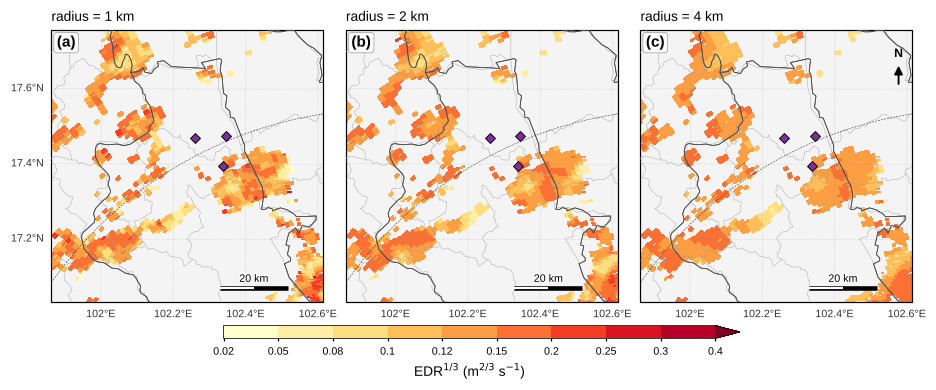

           n_gates    p50    p95    max  time_s
radius_km                                      
1            32806  0.124  0.199  0.331   5.055
2            34057  0.127  0.187  0.283   4.967
4            34926  0.129  0.179  0.283   5.286

→ R เล็ก: ค่าสูงสุดมากกว่า (เห็นจุดเล็ก) แต่ noise มาก | R ใหญ่: เรียบ ค่าสูงสุดถูกเฉลี่ยลง
  งานเตือนภัยการบิน → R เล็ก (1–2 km) ; สถิติภูมิอากาศ/เปรียบเทียบหลายพายุ → R ใหญ่ (2–4 km) และต้องรายงานค่า R ในงานวิจัยเสมอ


In [12]:
#@title ✅ เฉลยแบบฝึกหัด 3.3
ZB = kt.box_around(meta, NK["lon"] - 0.1, NK["lat"], 40)
res = []
fig, axs = mp.map_panels(1, 3, meta, panel_width=2.8, zoom=ZB)
for k, R in enumerate((1, 2, 4)):
    t0 = time.time()
    pt.add_edr(radar, radius=R, name=f"EDR_{R}")
    dt = time.time() - t0
    e_ = pt.field_data(radar, f"EDR_{R}")
    res.append({"radius_km": R, "n_gates": int(np.isfinite(e_).sum()), "p50": np.nanpercentile(e_, 50),
                "p95": np.nanpercentile(e_, 95), "max": np.nanmax(e_), "time_s": dt})
    im = pt.ppi_map(axs[k], radar, f"EDR_{R}", 1, meta, kind="EDR", zoom=ZB, title=f"radius = {R} km",
                    north=(k == 2), gridline_labels=("left", "bottom") if k == 0 else ("bottom",))
    mp.add_reports(axs[k], reports, legend=False)
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs)
mp.save_figure(fig, "nb3_ex33_radius")
plt.show()
res = pd.DataFrame(res).set_index("radius_km").round(3)
print(res)
print("\n→ R เล็ก: ค่าสูงสุดมากกว่า (เห็นจุดเล็ก) แต่ noise มาก | R ใหญ่: เรียบ ค่าสูงสุดถูกเฉลี่ยลง"
      "\n  งานเตือนภัยการบิน → R เล็ก (1–2 km) ; สถิติภูมิอากาศ/เปรียบเทียบหลายพายุ → R ใหญ่ (2–4 km) และต้องรายงานค่า R ในงานวิจัยเสมอ")

---
## 📝 สรุป
- $\sigma_v$ ดิบ **เพิ่มตามระยะ** จากขนาดลำคลื่น จึงต้องแปลงเป็น EDR ก่อนเปรียบเทียบ — NTDA ใน PyTDA ทำให้ EDR แทบไม่ขึ้นกับระยะ
- ในพายุ 3 พ.ค. 2567 EDR ส่วนใหญ่อยู่ระดับ **เบา (0.1–0.2 m$^{2/3}$ s⁻¹)** มีจุดระดับปานกลางในแกนพายุและระดับกลาง–บน
- EDR สัมพันธ์กับ **shear ของลม** มากกว่า reflectivity — สอดคล้องกับฟิสิกส์ของการเกิดความปั่นป่วน
- ผลไวต่อพารามิเตอร์ (`radius`) → ต้องระบุในรายงานและเลือกให้เหมาะกับคำถามวิจัย

### ❓ คำถามชวนคิด
1. ทำไมสนามบินจึงสนใจทั้ง **downburst (NB2)** และ **EDR (NB3)**? สองอย่างนี้ต่างกันอย่างไรในมุมความปลอดภัยการบิน?
2. ถ้า KKN มี $V_{ny}$ ต่ำ ความเร็วที่พับ **มีผลต่อ $\sigma_v$ หรือไม่?** (คำใบ้: สเปกตรัมกว้างมากจนเกิน $2V_{ny}$ ได้หรือไม่)
3. EDR สูงที่ระดับ 6–9 km เหนือนากลาง สอดคล้องกับชนิดหยาดน้ำฟ้าแบบใด (จะเห็นใน NB5)?

**🚀 ต่อยอด (ป.โท):** ใช้ตาราง `data/derived/KKN_20240503_volume_metrics.csv` (คอลัมน์ `edr_p95`) ร่วมกับเส้นทางบินเข้า–ออกท่าอากาศยานขอนแก่นและอุดรธานี
เพื่อประเมินว่าช่วงเวลาใดของวันมีความเสี่ยงต่อการบิน — และเปรียบเทียบกับรายงานของนักบิน (PIREP) ถ้ามี

### 📚 เอกสารอ้างอิง
- Doviak, R. J., & Zrnić, D. S. (1993). *Doppler Radar and Weather Observations*. Academic Press. (บทที่ 5 และ 10)
- Istok, M. J., & Doviak, R. J. (1986). Analysis of the relation between Doppler spectral width and thunderstorm turbulence. *J. Atmos. Sci.*, 43, 2199–2214.
- Williams, J. K., & Meymaris, G. (2016). Remote turbulence detection using ground-based Doppler weather radar. In *Aviation Turbulence* (pp. 149–177). Springer.
- Lang, T. J., et al. — PyTDA: Python Turbulence Detection Algorithm. https://github.com/nasa/PyTDA
- ICAO (2018). *Annex 3 — Meteorological Service for International Air Navigation* (EDR reporting).